Proyecto Olist ML
Predicción de retrasos logísticos y segmentación de clientes

Institución: Universidad de Cundinamarca

Programa: Ingeniería de Sistemas

Asignatura: Ciencia de Datos

Integrantes: Juan David Aguilar Páez y Nicolas Mauricio Vasquez

Cuadernillo: 06 - evaluacion integral


# Evaluación integral del proyecto Olist

## Integración de aprendizaje supervisado y no supervisado

### Objetivo

Consolidar y analizar los resultados obtenidos durante las
etapas de modelado supervisado y segmentación de clientes.

Se busca interpretar los principales hallazgos, reconocer las
limitaciones metodológicas y establecer conclusiones
fundamentadas en los experimentos realizados.

### Enfoques desarrollados

**Aprendizaje supervisado:** predicción del riesgo de retraso
en la entrega de pedidos.

**Aprendizaje no supervisado:** identificación de perfiles
de compradores mediante indicadores RFM y K-Means.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

ruta_resultados = Path("../resultados")

archivos = sorted(
    archivo.name
    for archivo in ruta_resultados.glob("*.csv")
)

print("Archivos de resultados disponibles:")

for archivo in archivos:
    print("-", archivo)

Archivos de resultados disponibles:
- comparacion_algoritmos_v3.csv
- resumen_segmentos_rfm.csv
- resumen_segmentos_rm.csv
- segmentacion_clientes.csv
- validacion_temporal_v3.csv


## 1. Carga y revisión de resultados

Se cargan los archivos generados durante el modelado
supervisado y la segmentación de clientes.

Antes de integrar sus resultados, se revisan las dimensiones,
columnas y primeras filas de cada archivo.

Esta comprobación permite identificar qué métricas y
características están disponibles para el análisis.

In [2]:
# Cargar los resultados de los cuadernillos anteriores

comparacion_v3 = pd.read_csv(
    ruta_resultados / "comparacion_algoritmos_v3.csv"
)

validacion_v3 = pd.read_csv(
    ruta_resultados / "validacion_temporal_v3.csv"
)

resumen_rm = pd.read_csv(
    ruta_resultados / "resumen_segmentos_rm.csv"
)

resumen_rfm = pd.read_csv(
    ruta_resultados / "resumen_segmentos_rfm.csv"
)

segmentacion = pd.read_csv(
    ruta_resultados / "segmentacion_clientes.csv"
)

# Organizar los archivos para revisarlos
tablas = {
    "Comparación de algoritmos V3": comparacion_v3,
    "Validación temporal V3": validacion_v3,
    "Segmentos RM": resumen_rm,
    "Segmentos RFM": resumen_rfm,
    "Segmentación de compradores": segmentacion
}

for nombre, tabla in tablas.items():
    print(f"\n--- {nombre} ---")
    print("Dimensiones:", tabla.shape)
    print("Columnas:", tabla.columns.tolist())
    display(tabla.head(3))


--- Comparación de algoritmos V3 ---
Dimensiones: (3, 4)
Columnas: ['Mes', 'Regresion_Logistica_V3', 'Random_Forest_V3', 'Diferencia_AP']


,Mes,Regresion_Logistica_V3,Random_Forest_V3,Diferencia_AP
0,2017-11,0.165929,0.113473,0.052456
1,2018-02,0.279538,0.259315,0.020222
2,2018-04,0.137947,0.129494,0.008453



--- Validación temporal V3 ---
Dimensiones: (3, 4)
Columnas: ['Mes', 'AP', 'Tasa_retraso', 'Lift_AP']


,Mes,AP,Tasa_retraso,Lift_AP
0,2017-11,0.165929,0.124040,1.337709
1,2018-02,0.279538,0.140479,1.989882
2,2018-04,0.137947,0.032417,4.255364



--- Segmentos RM ---
Dimensiones: (3, 7)
Columnas: ['segmento', 'compradores', 'recencia_mediana', 'frecuencia_mediana', 'gasto_mediano', 'gasto_promedio', 'porcentaje']


,segmento,compradores,recencia_mediana,frecuencia_mediana,gasto_mediano,gasto_promedio,porcentaje
0,0,16380,37.0,1.0,106.32,136.92,17.55
1,1,43791,270.0,1.0,67.13,69.71,46.91
2,2,33186,251.0,1.0,206.87,305.16,35.55



--- Segmentos RFM ---
Dimensiones: (3, 7)
Columnas: ['segmento', 'compradores', 'recencia_mediana', 'frecuencia_mediana', 'gasto_mediano', 'gasto_promedio', 'porcentaje']


,segmento,compradores,recencia_mediana,frecuencia_mediana,gasto_mediano,gasto_promedio,porcentaje
0,0,19093,44.0,1.0,108.43,165.62,20.45
1,1,71463,270.0,1.0,104.87,159.47,76.55
2,2,2801,199.0,2.0,225.55,308.59,3.00



--- Segmentación de compradores ---
Dimensiones: (93357, 6)
Columnas: ['customer_unique_id', 'recencia_dias', 'frecuencia', 'gasto_total', 'segmento_rm', 'segmento_rfm']


,customer_unique_id,recencia_dias,frecuencia,gasto_total,segmento_rm,segmento_rfm
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,1,1
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1


## 2. Evaluación integral del aprendizaje supervisado

### Comparación de Average Precision con la tasa de retraso

Se integran los resultados de validación temporal con la
comparación de algoritmos de la versión V3.

Se analiza el desempeño de la regresión logística y
Random Forest frente a la tasa de retraso de cada período.

La comparación permite interpretar los resultados teniendo
en cuenta el desbalance de clases y los cambios temporales.

In [3]:
# Integrar los resultados de validación y comparación

evaluacion_supervisada = comparacion_v3.merge(
    validacion_v3[
        ["Mes", "Tasa_retraso", "Lift_AP"]
    ],
    on="Mes",
    how="inner",
    validate="one_to_one"
)

# Ordenar los períodos
evaluacion_supervisada = (
    evaluacion_supervisada
    .sort_values("Mes")
    .reset_index(drop=True)
)

print("Evaluación integral supervisada:")
display(evaluacion_supervisada.round(4))

# Comprobar diferencias entre los algoritmos
print(
    "\nPeríodos donde Regresión Logística supera a Random Forest:",
    (
        evaluacion_supervisada["Regresion_Logistica_V3"]
        > evaluacion_supervisada["Random_Forest_V3"]
    ).sum()
)

Evaluación integral supervisada:


,Mes,Regresion_Logistica_V3,Random_Forest_V3,Diferencia_AP,Tasa_retraso,Lift_AP
0,2017-11,0.1659,0.1135,0.0525,0.1240,1.3377
1,2018-02,0.2795,0.2593,0.0202,0.1405,1.9899
2,2018-04,0.1379,0.1295,0.0085,0.0324,4.2554



Períodos donde Regresión Logística supera a Random Forest: 3


### Visualización temporal de los modelos supervisados

Se comparan los resultados de Average Precision de la
regresión logística V3 y Random Forest V3 en tres períodos
de validación temporal.

Se incluye la tasa de retraso como referencia para
interpretar las métricas considerando el desbalance de clases.

Las diferencias entre períodos se analizan de manera
descriptiva, sin asumir que representan un rendimiento
garantizado sobre datos futuros.

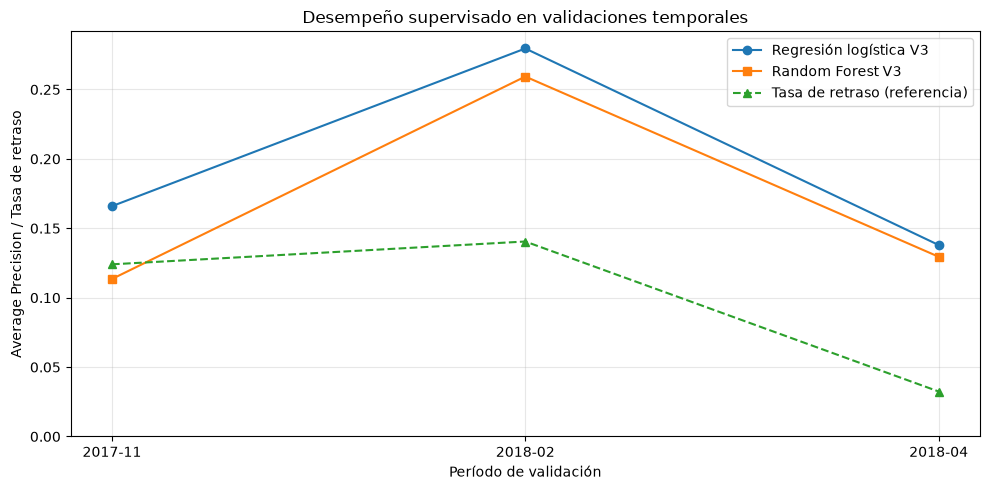

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(
    evaluacion_supervisada["Mes"],
    evaluacion_supervisada["Regresion_Logistica_V3"],
    marker="o",
    label="Regresión logística V3"
)

plt.plot(
    evaluacion_supervisada["Mes"],
    evaluacion_supervisada["Random_Forest_V3"],
    marker="s",
    label="Random Forest V3"
)

plt.plot(
    evaluacion_supervisada["Mes"],
    evaluacion_supervisada["Tasa_retraso"],
    marker="^",
    linestyle="--",
    label="Tasa de retraso (referencia)"
)

plt.title("Desempeño supervisado en validaciones temporales")
plt.xlabel("Período de validación")
plt.ylabel("Average Precision / Tasa de retraso")
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Evaluación integral del aprendizaje no supervisado

### Comparación de los perfiles RM y RFM

Se consolidan los resultados de segmentación obtenidos
mediante K-Means con tres grupos.

Se comparan los tamaños de los segmentos, la recencia
mediana, la frecuencia mediana y el gasto mediano.

Los modelos RM y RFM se analizan por separado porque
utilizan diferentes características para formar sus grupos.

In [6]:
# Seleccionar indicadores relevantes de cada modelo
columnas = [
    "segmento",
    "compradores",
    "porcentaje",
    "recencia_mediana",
    "frecuencia_mediana",
    "gasto_mediano"
]

# Identificar el modelo de origen
perfiles_rm = resumen_rm[columnas].copy()
perfiles_rm["modelo"] = "RM"

perfiles_rfm = resumen_rfm[columnas].copy()
perfiles_rfm["modelo"] = "RFM"

# Unir los perfiles en una sola tabla
comparacion_segmentos = pd.concat(
    [perfiles_rm, perfiles_rfm],
    ignore_index=True
)

# Organizar columnas
comparacion_segmentos = comparacion_segmentos[
    [
        "modelo",
        "segmento",
        "compradores",
        "porcentaje",
        "recencia_mediana",
        "frecuencia_mediana",
        "gasto_mediano"
    ]
]

print("Comparación de perfiles RM y RFM:")
display(comparacion_segmentos)

print("\nTotal de compradores por modelo:")
print(
    comparacion_segmentos.groupby("modelo")["compradores"].sum()
)

Comparación de perfiles RM y RFM:


,modelo,segmento,compradores,porcentaje,recencia_mediana,frecuencia_mediana,gasto_mediano
0,RM,0,16380,17.55,37.0,1.0,106.32
1,RM,1,43791,46.91,270.0,1.0,67.13
2,RM,2,33186,35.55,251.0,1.0,206.87
3,RFM,0,19093,20.45,44.0,1.0,108.43
4,RFM,1,71463,76.55,270.0,1.0,104.87
5,RFM,2,2801,3.00,199.0,2.0,225.55



Total de compradores por modelo:
modelo
RFM    93357
RM     93357
Name: compradores, dtype: int64


### Distribución porcentual de los segmentos

Se comparan los porcentajes de compradores asignados a
cada segmento en los modelos RM y RFM.

El objetivo es mostrar cómo cambia la distribución de
los grupos al incorporar la frecuencia como característica
de K-Means.

Los números de los segmentos son identificadores internos
de cada modelo y no representan perfiles equivalentes.

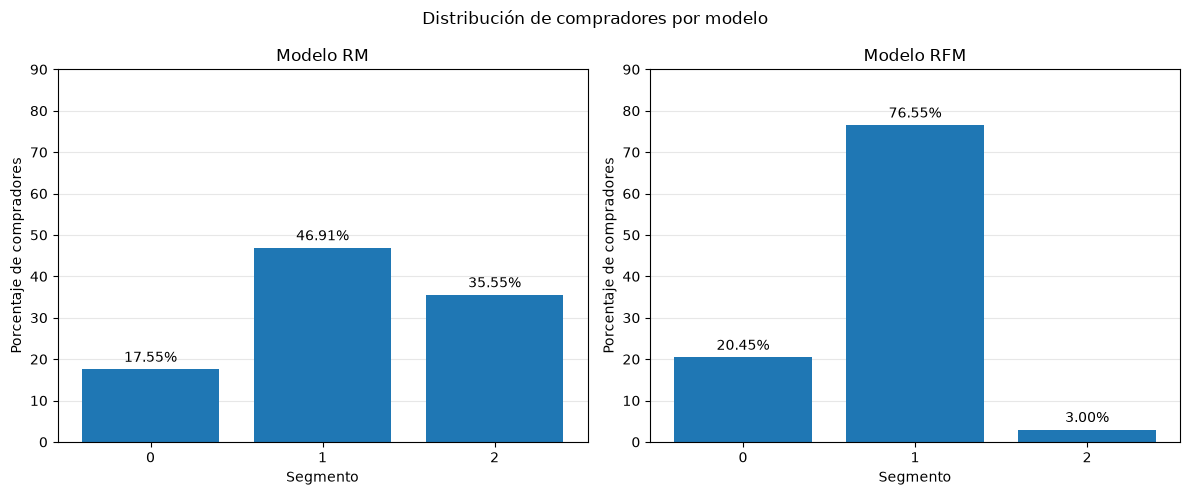

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for eje, datos, nombre in zip(
    ax,
    [resumen_rm, resumen_rfm],
    ["Modelo RM", "Modelo RFM"]
):
    barras = eje.bar(
        datos["segmento"].astype(str),
        datos["porcentaje"]
    )

    eje.bar_label(
        barras,
        fmt="%.2f%%",
        padding=3
    )

    eje.set_title(nombre)
    eje.set_xlabel("Segmento")
    eje.set_ylabel("Porcentaje de compradores")
    eje.set_ylim(0, 90)
    eje.grid(axis="y", alpha=0.3)
    eje.set_axisbelow(True)

plt.suptitle("Distribución de compradores por modelo")
plt.tight_layout()
plt.show()

## 4. Síntesis de los hallazgos del proyecto

Se consolidan los principales resultados del aprendizaje
supervisado y no supervisado.

Cada hallazgo se acompaña de su interpretación y de una
limitación metodológica.

El objetivo es comunicar qué se encontró realmente
y qué aspectos requieren validación adicional.

In [8]:
hallazgos = pd.DataFrame([
    {
        "Enfoque": "Supervisado",
        "Hallazgo": "Regresión logística V3 superó a Random Forest V3",
        "Evidencia": "Mayor AP en los 3 períodos evaluados",
        "Limitación": "Resultados de validación temporal exploratoria"
    },
    {
        "Enfoque": "Supervisado",
        "Hallazgo": "El rendimiento varió entre períodos",
        "Evidencia": "AP logística entre 0.1379 y 0.2795",
        "Limitación": "No garantiza generalización a nuevos períodos"
    },
    {
        "Enfoque": "No supervisado",
        "Hallazgo": "RM identificó tres perfiles de compradores",
        "Evidencia": "93.357 compradores distribuidos en 3 segmentos",
        "Limitación": "La utilidad comercial no ha sido validada"
    },
    {
        "Enfoque": "No supervisado",
        "Hallazgo": "La frecuencia distingue a pocos compradores",
        "Evidencia": "97 % realizó una sola compra registrada",
        "Limitación": "El historial de compras es limitado"
    },
    {
        "Enfoque": "No supervisado",
        "Hallazgo": "RFM separó a los compradores recurrentes",
        "Evidencia": "2.801 compradores en un segmento exclusivo",
        "Limitación": "La separación también se obtiene con frecuencia > 1"
    }
])

display(hallazgos)

,Enfoque,Hallazgo,Evidencia,Limitación
0,Supervisado,Regresión logística V3 superó a Random Forest V3,Mayor AP en los 3 períodos evaluados,Resultados de validación temporal exploratoria
1,Supervisado,El rendimiento varió entre períodos,AP logística entre 0.1379 y 0.2795,No garantiza generalización a nuevos períodos
2,No supervisado,RM identificó tres perfiles de compradores,93.357 compradores distribuidos en 3 segmentos,La utilidad comercial no ha sido validada
3,No supervisado,La frecuencia distingue a pocos compradores,97 % realizó una sola compra registrada,El historial de compras es limitado
4,No supervisado,RFM separó a los compradores recurrentes,2.801 compradores en un segmento exclusivo,La separación también se obtiene con frecuenci...


## 5. Posibles aplicaciones de los resultados

A partir de los hallazgos supervisados y no supervisados,
se plantean posibles aplicaciones para apoyar decisiones
en una plataforma de comercio electrónico.

Estas propuestas son hipótesis de uso y no representan
estrategias implementadas ni beneficios comerciales
demostrados.

Su utilidad deberá comprobarse mediante evaluaciones
adicionales.

In [9]:
aplicaciones = pd.DataFrame([
    {
        "Enfoque": "Supervisado",
        "Resultado": "Predicción de retrasos",
        "Aplicacion_propuesta": "Priorizar pedidos con mayor riesgo para revisión logística",
        "Validacion_pendiente": "Evaluar el modelo en datos futuros independientes"
    },
    {
        "Enfoque": "No supervisado",
        "Resultado": "Compradores recientes",
        "Aplicacion_propuesta": "Investigar estrategias de recompra",
        "Validacion_pendiente": "Comprobar resultados mediante pruebas comerciales"
    },
    {
        "Enfoque": "No supervisado",
        "Resultado": "Compradores menos recientes de bajo gasto",
        "Aplicacion_propuesta": "Evaluar campañas de reactivación",
        "Validacion_pendiente": "Medir respuesta y rentabilidad de las campañas"
    },
    {
        "Enfoque": "No supervisado",
        "Resultado": "Compradores menos recientes de alto gasto",
        "Aplicacion_propuesta": "Estudiar estrategias de atención personalizada",
        "Validacion_pendiente": "Comprobar su efecto en la retención y el valor del cliente"
    },
    {
        "Enfoque": "No supervisado",
        "Resultado": "Compradores recurrentes",
        "Aplicacion_propuesta": "Investigar programas de fidelización",
        "Validacion_pendiente": "Medir recompra y beneficios frente a un grupo de control"
    }
])

print("Aplicaciones potenciales del proyecto:")
display(aplicaciones)

Aplicaciones potenciales del proyecto:


,Enfoque,Resultado,Aplicacion_propuesta,Validacion_pendiente
0,Supervisado,Predicción de retrasos,Priorizar pedidos con mayor riesgo para revisi...,Evaluar el modelo en datos futuros independientes
1,No supervisado,Compradores recientes,Investigar estrategias de recompra,Comprobar resultados mediante pruebas comerciales
2,No supervisado,Compradores menos recientes de bajo gasto,Evaluar campañas de reactivación,Medir respuesta y rentabilidad de las campañas
3,No supervisado,Compradores menos recientes de alto gasto,Estudiar estrategias de atención personalizada,Comprobar su efecto en la retención y el valor...
4,No supervisado,Compradores recurrentes,Investigar programas de fidelización,Medir recompra y beneficios frente a un grupo ...


## 6. Limitaciones generales del proyecto

Se identifican las principales limitaciones relacionadas
con los datos, el aprendizaje supervisado y la segmentación.

El propósito es reconocer los aspectos que pueden afectar
la interpretación y generalización de los resultados.

Estas limitaciones orientan las recomendaciones para
trabajos futuros.

In [10]:
limitaciones = pd.DataFrame([
    {
        "Area": "Datos",
        "Limitacion": "Conjunto de datos histórico",
        "Implicacion": "Los patrones pueden cambiar en otros períodos"
    },
    {
        "Area": "Aprendizaje supervisado",
        "Limitacion": "Mejoras V3 evaluadas de forma exploratoria",
        "Implicacion": "Falta confirmación en una prueba futura independiente"
    },
    {
        "Area": "Aprendizaje supervisado",
        "Limitacion": "Desbalance de clases y cambios temporales",
        "Implicacion": "La detección de retrasos puede variar entre períodos"
    },
    {
        "Area": "Aprendizaje supervisado",
        "Limitacion": "Calibración de probabilidades no consolidada",
        "Implicacion": "Las puntuaciones no deben asumirse como probabilidades confiables"
    },
    {
        "Area": "Segmentación",
        "Limitacion": "El 97 % de compradores registra una sola compra",
        "Implicacion": "La frecuencia aporta poca diferenciación para la mayoría"
    },
    {
        "Area": "Segmentación",
        "Limitacion": "Presencia de gastos monetarios extremos",
        "Implicacion": "Pueden influir en los grupos formados por K-Means"
    },
    {
        "Area": "Aplicación práctica",
        "Limitacion": "No se han probado intervenciones comerciales",
        "Implicacion": "No es posible afirmar beneficios operativos o económicos"
    }
])

print("Limitaciones generales:")
display(limitaciones)

Limitaciones generales:


,Area,Limitacion,Implicacion
0,Datos,Conjunto de datos histórico,Los patrones pueden cambiar en otros períodos
1,Aprendizaje supervisado,Mejoras V3 evaluadas de forma exploratoria,Falta confirmación en una prueba futura indepe...
2,Aprendizaje supervisado,Desbalance de clases y cambios temporales,La detección de retrasos puede variar entre pe...
3,Aprendizaje supervisado,Calibración de probabilidades no consolidada,Las puntuaciones no deben asumirse como probab...
4,Segmentación,El 97 % de compradores registra una sola compra,La frecuencia aporta poca diferenciación para ...
5,Segmentación,Presencia de gastos monetarios extremos,Pueden influir en los grupos formados por K-Means
6,Aplicación práctica,No se han probado intervenciones comerciales,No es posible afirmar beneficios operativos o ...


## 7. Conclusiones integrales del proyecto Olist

### 7.1. Comprensión y preparación de los datos

El proyecto permitió analizar información histórica de la
plataforma brasileña de comercio electrónico Olist,
integrando datos sobre pedidos, clientes, productos,
vendedores, entregas y pagos.

Durante la preparación se identificaron relaciones entre
tablas, valores faltantes y condiciones necesarias para
construir las variables utilizadas en los modelos.

Esta etapa fue fundamental para desarrollar análisis
supervisados y no supervisados sobre información consistente.

### 7.2. Aprendizaje supervisado: predicción de retrasos

Se desarrollaron y evaluaron diferentes algoritmos para
identificar pedidos con riesgo de llegar después de la
fecha estimada de entrega.

En las validaciones temporales exploratorias de la versión
V3, la regresión logística obtuvo una Average Precision
superior a Random Forest en los tres períodos estudiados:

- Noviembre de 2017: AP = 0,1659.
- Febrero de 2018: AP = 0,2795.
- Abril de 2018: AP = 0,1379.

La incorporación de nuevas características permitió
obtener mejoras experimentales respecto a las versiones
anteriores.

Sin embargo, el rendimiento varió entre períodos y estas
mejoras todavía no se han confirmado mediante una prueba
final independiente posterior a su desarrollo.

Por tanto, el modelo debe considerarse un candidato
experimental y no una solución lista para producción.

### 7.3. Aprendizaje no supervisado: segmentación de clientes

Se construyeron indicadores de recencia, frecuencia y valor
monetario para 93.357 compradores con pedidos entregados
e información de pago registrada.

El análisis mostró que el 97 % de los compradores realizó
una sola compra registrada, lo que limitó la variabilidad
del indicador de frecuencia.

Se compararon dos alternativas de segmentación:

- RM: recencia y gasto monetario.
- RFM: recencia, frecuencia y gasto monetario.

Se seleccionó experimentalmente el modelo RM con K=3
por su capacidad para identificar tres perfiles
interpretables:

1. Compradores recientes.
2. Compradores menos recientes de bajo gasto.
3. Compradores menos recientes de alto gasto.

El modelo RFM con K=3 se conservó como alternativa
complementaria porque separó a los 2.801 compradores
recurrentes en un segmento exclusivo.

Ambos modelos presentaron alta estabilidad frente a los
cambios de inicialización evaluados.

### 7.4. Integración de los hallazgos

Los dos enfoques de Machine Learning permitieron estudiar
problemas diferentes del comercio electrónico.

El aprendizaje supervisado exploró la posibilidad de
identificar pedidos con mayor riesgo de retraso.

El aprendizaje no supervisado permitió describir perfiles
históricos de compradores según su comportamiento de compra.

En conjunto, estos análisis aportan información que podría
orientar investigaciones futuras sobre logística y
segmentación comercial.

No obstante, sus resultados no demuestran todavía mejoras
operativas o económicas en una plataforma real.

### 7.5. Limitaciones del proyecto

Las principales limitaciones identificadas fueron:

- Uso de datos históricos.
- Cambios temporales en la distribución de retrasos.
- Desbalance de clases.
- Falta de una prueba final independiente para las mejoras V3.
- Calibración de probabilidades no consolidada.
- Baja frecuencia de recompra registrada.
- Influencia potencial de valores monetarios extremos.
- Ausencia de validaciones comerciales de los segmentos.

Estas condiciones deben considerarse al interpretar los
resultados y antes de proponer su utilización práctica.

### 7.6. Recomendaciones para trabajos futuros

Se recomienda:

1. Evaluar los modelos supervisados mejorados sobre un
   período independiente posterior al desarrollo.
2. Investigar nuevas características predictivas
   disponibles en el momento de realizar la compra.
3. Analizar la calibración y los costos de falsas alarmas
   en la priorización logística.
4. Evaluar la estabilidad de los segmentos con nuevos
   períodos o conjuntos de compradores.
5. Estudiar alternativas de segmentación que consideren
   la baja frecuencia de recompra registrada.
6. Validar experimentalmente cualquier estrategia comercial
   derivada de los segmentos.

### 7.7. Conclusión general

El proyecto permitió desarrollar un proceso de Ciencia
de Datos que integró comprensión, exploración, preparación,
modelado supervisado, aprendizaje no supervisado y
evaluación de resultados.

Más allá de las métricas obtenidas, uno de los principales
aprendizajes fue la importancia de seleccionar correctamente
los datos, prevenir fugas de información, utilizar
evaluaciones apropiadas e interpretar críticamente
los resultados.

Los modelos desarrollados ofrecen hallazgos exploratorios
sobre los retrasos logísticos y el comportamiento de
compra en Olist.

Su principal contribución, en esta etapa, es demostrar
un proceso reproducible y fundamentado de análisis de datos,
reconociendo las limitaciones que deben resolverse antes
de considerar aplicaciones reales.